In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set/colon_image_sets/colon_aca/colonca637.jpeg
/kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set/colon_image_sets/colon_aca/colonca3400.jpeg
/kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set/colon_image_sets/colon_aca/colonca783.jpeg
/kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set/colon_image_sets/colon_aca/colonca3927.jpeg
/kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set/colon_image_sets/colon_aca/colonca4109.jpeg
/kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set/colon_image_sets/colon_aca/colonca95.jpeg
/kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set/colon_image_sets/colon_aca/colonc

In [2]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

In [3]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

import time
import random
import warnings
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as mpl_cm
import seaborn as sns
import cv2
warnings.filterwarnings('ignore')

print("✅ Standard libraries imported")

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

print("✅ TensorFlow imported")

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score, roc_auc_score
)
from sklearn.preprocessing import label_binarize

print("✅ scikit-learn imported")

# ── Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ── Constants
IMG_SIZE    = 224
BATCH_SIZE  = 32
EPOCHS      = 50
NUM_CLASSES = 3
CLASS_NAMES = ['adenocarcinoma', 'squamous_cell_carcinoma', 'benign']
L2_REG      = 1e-4
INIT_LR     = 3e-4
LAST_CONV   = 'dsc4_pw_relu'
OUT_DIR     = '/kaggle/working'
AUTOTUNE    = tf.data.AUTOTUNE

print(f"\nTensorFlow  : {tf.__version__}")
print(f"GPU devices : {tf.config.list_physical_devices('GPU')}")
print(f"Image size  : {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch size  : {BATCH_SIZE}")
print(f"\n✅ Section 1 complete — all imports OK")

✅ Standard libraries imported


E0000 00:00:1776014536.828521      16 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1776014536.873709      16 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1776014537.263977      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776014537.264028      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776014537.264031      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776014537.264033      16 computation_placer.cc:177] computation placer already registered. Please check linka

✅ TensorFlow imported
✅ scikit-learn imported

TensorFlow  : 2.19.0
GPU devices : []
Image size  : 224x224
Batch size  : 32

✅ Section 1 complete — all imports OK


In [4]:
# ── Find lung class directories anywhere under /kaggle/input
FOLDER_MAP = {
    'lung_aca': 'adenocarcinoma',
    'lung_scc': 'squamous_cell_carcinoma',
    'lung_n'  : 'benign',
}

lung_dirs = {}
for dirpath, dirnames, filenames in os.walk('/kaggle/input'):
    folder_name = os.path.basename(dirpath)
    if folder_name in FOLDER_MAP:
        label = FOLDER_MAP[folder_name]
        lung_dirs[label] = dirpath

# ── Validate
if len(lung_dirs) == 0:
    print("ERROR: No lung folders found under /kaggle/input")
    print("Please add: andrewmvd/lung-and-colon-cancer-histopathological-images")
    print("\nSearching what IS available:")
    for root, dirs, files in os.walk('/kaggle/input'):
        depth = root.replace('/kaggle/input', '').count(os.sep)
        if depth < 3:
            print(f"  {'  '*depth}{os.path.basename(root)}/  ({len(files)} files)")
    raise SystemExit("Add the dataset and re-run.")

print(f"Found {len(lung_dirs)} lung class folders:")
for label, d in lung_dirs.items():
    exts = ['*.jpeg','*.jpg','*.png','*.JPEG','*.JPG','*.PNG']
    n = sum(len(glob.glob(os.path.join(d, e))) for e in exts)
    print(f"  {label:<35} {n:>6,} images  →  {d}")

Found 3 lung class folders:
  adenocarcinoma                       5,000 images  →  /kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set/lung_image_sets/lung_aca
  squamous_cell_carcinoma              5,000 images  →  /kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set/lung_image_sets/lung_scc
  benign                               5,000 images  →  /kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set/lung_image_sets/lung_n


Total images loaded : 15,000

Split  →  Train: 10,500  |  Val: 2,250  |  Test: 2,250

Class distribution per split:
  Train : adenocarcinoma=3500  squamous=3500  benign=3500
  Val   : adenocarcinoma=750  squamous=750  benign=750
  Test  : adenocarcinoma=750  squamous=750  benign=750


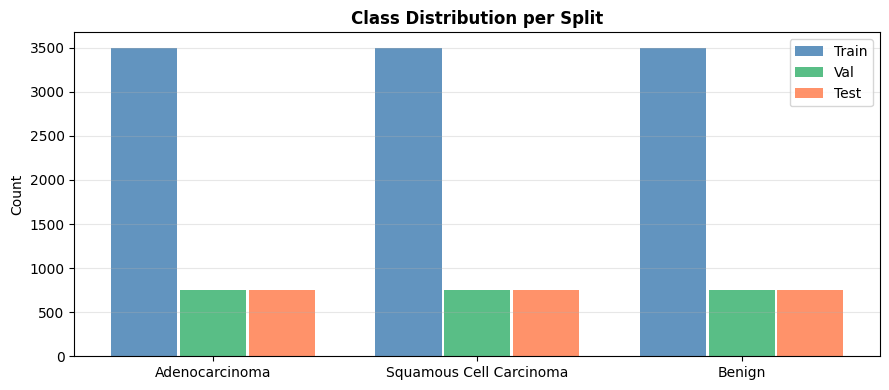


✅ Section 2 complete


In [5]:
# ── Build flat file list
EXTS = ['*.jpeg','*.jpg','*.png','*.JPEG','*.JPG','*.PNG']

all_paths, all_labels = [], []
for label_name, dir_path in lung_dirs.items():
    files = []
    for ext in EXTS:
        files += glob.glob(os.path.join(dir_path, ext))
    if len(files) == 0:
        raise ValueError(f"No image files found in {dir_path}")
    idx = CLASS_NAMES.index(label_name)
    all_paths  += files
    all_labels += [idx] * len(files)

all_paths  = np.array(all_paths)
all_labels = np.array(all_labels, dtype=np.int32)
print(f"Total images loaded : {len(all_paths):,}")

# ── Stratified 70 / 15 / 15
X_train, X_temp, y_train, y_temp = train_test_split(
    all_paths, all_labels,
    test_size=0.30, stratify=all_labels, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50, stratify=y_temp, random_state=SEED
)

print(f"\nSplit  →  Train: {len(X_train):,}  |  Val: {len(X_val):,}  |  Test: {len(X_test):,}")
print("\nClass distribution per split:")
for split_name, ys in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    c = np.bincount(ys)
    row = '  '.join(f"{CLASS_NAMES[i].split('_')[0]}={c[i]}" for i in range(NUM_CLASSES))
    print(f"  {split_name:<6}: {row}")

# ── Class balance chart
fig, ax = plt.subplots(figsize=(9, 4))
nice_names = [c.replace('_',' ').title() for c in CLASS_NAMES]
x = np.arange(NUM_CLASSES)
for i, (split, ys, color) in enumerate([
    ('Train', y_train, 'steelblue'),
    ('Val',   y_val,   'mediumseagreen'),
    ('Test',  y_test,  'coral')
]):
    ax.bar(x + i*0.26 - 0.26, np.bincount(ys), 0.25, label=split, color=color, alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(nice_names)
ax.set_title('Class Distribution per Split', fontweight='bold')
ax.set_ylabel('Count'); ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/class_distribution.png', dpi=130, bbox_inches='tight')
plt.show()
print("\n✅ Section 2 complete")

train_ds : 329 batches
val_ds   : 71 batches
test_ds  : 71 batches


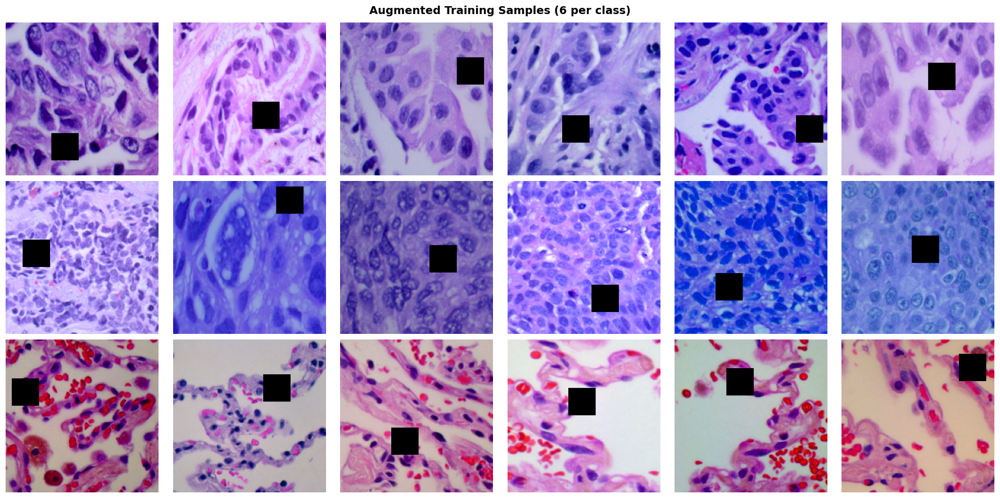

✅ Section 3 complete


In [6]:
@tf.function
def parse_image(path, label):
    """Load → decode → resize → normalise → one-hot."""
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    lbl = tf.one_hot(label, NUM_CLASSES)
    return img, lbl


@tf.function
def augment(img, lbl):
    """Strong augmentation applied only to training images."""
    # Flip
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)

    # Random 90-degree rotation (0 / 90 / 180 / 270)
    k = tf.random.uniform([], 0, 4, dtype=tf.int32)
    img = tf.image.rot90(img, k)

    # Random zoom: crop then resize back
    crop_frac = tf.random.uniform([], 0.80, 1.00)
    crop_size = tf.cast(tf.cast(IMG_SIZE, tf.float32) * crop_frac, tf.int32)
    img = tf.image.random_crop(img, [crop_size, crop_size, 3])
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])

    # Colour jitter
    img = tf.image.random_brightness(img, max_delta=0.20)
    img = tf.image.random_contrast(img, lower=0.75, upper=1.25)
    img = tf.image.random_saturation(img, lower=0.75, upper=1.25)
    img = tf.image.random_hue(img, max_delta=0.08)
    img = tf.clip_by_value(img, 0.0, 1.0)

    # Cutout: zero a random 40x40 patch
    CUT = 40
    top  = tf.random.uniform([], 0, IMG_SIZE - CUT, dtype=tf.int32)
    left = tf.random.uniform([], 0, IMG_SIZE - CUT, dtype=tf.int32)
    mask_top = tf.ones([top, IMG_SIZE, 3])
    mask_mid = tf.concat([
        tf.ones([CUT, left, 3]),
        tf.zeros([CUT, CUT, 3]),
        tf.ones([CUT, IMG_SIZE - left - CUT, 3])
    ], axis=1)
    mask_bot = tf.ones([IMG_SIZE - top - CUT, IMG_SIZE, 3])
    mask = tf.concat([mask_top, mask_mid, mask_bot], axis=0)
    img = img * mask

    return img, lbl


def make_dataset(paths, labels, do_augment=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(parse_image, num_parallel_calls=AUTOTUNE)
    if do_augment:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_dataset(X_train, y_train, do_augment=True,  shuffle=True)
val_ds   = make_dataset(X_val,   y_val,   do_augment=False, shuffle=False)
test_ds  = make_dataset(X_test,  y_test,  do_augment=False, shuffle=False)

print(f"train_ds : {len(train_ds)} batches")
print(f"val_ds   : {len(val_ds)} batches")
print(f"test_ds  : {len(test_ds)} batches")

# Preview augmented samples
sample_imgs, sample_lbls = next(iter(train_ds))
imgs_np = sample_imgs.numpy()
lbls_np = np.argmax(sample_lbls.numpy(), axis=1)

fig, axes = plt.subplots(3, 6, figsize=(18, 9))
fig.suptitle('Augmented Training Samples (6 per class)', fontsize=14, fontweight='bold')
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    idxs = np.where(lbls_np == cls_idx)[0][:6]
    for j, idx in enumerate(idxs):
        ax = axes[cls_idx][j]
        ax.imshow(imgs_np[idx])
        if j == 0:
            ax.set_ylabel(cls_name.replace('_','\n').title(), fontsize=8, fontweight='bold')
        ax.axis('off')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/augmented_samples.png', dpi=120, bbox_inches='tight')
plt.show()
print("✅ Section 3 complete")

In [7]:
def dsc_block(x, filters, stride=1, name='dsc'):
    x = layers.DepthwiseConv2D(
        (3,3), strides=stride, padding='same', use_bias=False,
        depthwise_regularizer=l2(L2_REG), name=f'{name}_dw'
    )(x)
    x = layers.BatchNormalization(name=f'{name}_dw_bn')(x)
    x = layers.Activation('relu6', name=f'{name}_dw_relu')(x)

    x = layers.Conv2D(
        filters, (1,1), padding='same', use_bias=False,
        kernel_regularizer=l2(L2_REG), name=f'{name}_pw'
    )(x)
    x = layers.BatchNormalization(name=f'{name}_pw_bn')(x)
    x = layers.Activation('relu6', name=f'{name}_pw_relu')(x)
    return x


def build_model():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='input')

    # 🔥 Stem
    x = layers.Conv2D(
        32, (3,3), strides=2, padding='same', use_bias=False,
        kernel_regularizer=l2(L2_REG), name='stem_conv'
    )(inputs)
    x = layers.BatchNormalization(name='stem_bn')(x)
    x = layers.Activation('relu6', name='stem_relu')(x)

    # 🔥 Backbone
    x = dsc_block(x,  64, stride=2, name='dsc1')
    x = dsc_block(x, 128, stride=2, name='dsc2')
    x = dsc_block(x, 256, stride=2, name='dsc3')

    x = layers.Dropout(0.20, name='dropout_mid')(x)

    x = dsc_block(x, 256, stride=1, name='dsc4')   # ⭐ Grad-CAM layer (DO NOT CHANGE)
    x = dsc_block(x, 512, stride=2, name='dsc5')

    # 🔥 Tuned for ~700K
    x = dsc_block(x, 512, stride=1, name='dsc6')
    x = dsc_block(x, 384, stride=1, name='dsc7')

    # 🔥 Head
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dropout(0.50, name='dropout_final')(x)

    outputs = layers.Dense(
        NUM_CLASSES, activation='softmax',
        kernel_regularizer=l2(L2_REG), name='predictions'
    )(x)

    return Model(inputs, outputs, name='MicroLung-Net-v700K')


# Build model
model = build_model()
model.summary()

# Parameter check
total_params = model.count_params()
print(f"\n{'='*50}")
print(f"Total parameters : {total_params:,}")
status = '✅ PASS (<1M)' if total_params < 1_000_000 else '❌ FAIL (>1M)'
print(f"Constraint check : {status}")
print(f"{'='*50}")
print("\n✅ Final 700K Model Ready")


Model: "MicroLung-Net-v700K"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input (InputLayer)          [(None, 224, 224, 3)]     0         
                                                                 
 stem_conv (Conv2D)          (None, 112, 112, 32)      864       
                                                                 
 stem_bn (BatchNormalizatio  (None, 112, 112, 32)      128       
 n)                                                              
                                                                 
 stem_relu (Activation)      (None, 112, 112, 32)      0         
                                                                 
 dsc1_dw (DepthwiseConv2D)   (None, 56, 56, 32)        288       
                                                                 
 dsc1_dw_bn (BatchNormaliza  (None, 56, 56, 32)        128       
 tion)                                         

In [8]:
# Cosine Decay: starts at 3e-4, smoothly decays to 1e-6
total_steps  = EPOCHS * len(train_ds)
cosine_decay = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=INIT_LR,
    decay_steps=total_steps,
    alpha=1e-6 / INIT_LR
)

model.compile(
    optimizer=Adam(learning_rate=cosine_decay, clipnorm=1.0),
    loss=CategoricalCrossentropy(label_smoothing=0.10),
    metrics=['accuracy', keras.metrics.AUC(name='auc')]
)

callbacks = [
    EarlyStopping(
        monitor='val_accuracy', patience=8,
        restore_best_weights=True, verbose=1
    ),
    ModelCheckpoint(
        filepath=f'{OUT_DIR}/best_model.keras',
        monitor='val_accuracy', save_best_only=True, verbose=0
    ),
]

print("🚀 Training started ...")
history = model.fit(
    train_ds,
   validation_data=val_ds,
   epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

# Overfit summary
best_ep    = int(np.argmax(history.history['val_accuracy']))
best_train = history.history['accuracy'][best_ep]
best_val   = history.history['val_accuracy'][best_ep]
gap        = best_train - best_val

print(f"\n{'='*50}")
print(f"Best epoch     : {best_ep + 1}")
print(f"Train accuracy : {best_train:.4f}")
print(f"Val accuracy   : {best_val:.4f}")
print(f"Gap            : {gap:+.4f}  {'✅ OK' if gap < 0.08 else '⚠️ Still large'}")
print(f"{'='*50}")
print("\n✅ Section 5 complete")

🚀 Training started ...
Epoch 1/50
329/329 [==============================] - 144s 426ms/step - loss: 0.8976 - accuracy: 0.7407 - auc: 0.9090 - val_loss: 1.6511 - val_accuracy: 0.3333 - val_auc: 0.5082
Epoch 2/50
329/329 [==============================] - 136s 414ms/step - loss: 0.7588 - accuracy: 0.8405 - auc: 0.9568 - val_loss: 3.0211 - val_accuracy: 0.3333 - val_auc: 0.4945
Epoch 3/50
329/329 [==============================] - 138s 419ms/step - loss: 0.7029 - accuracy: 0.8762 - auc: 0.9702 - val_loss: 0.6528 - val_accuracy: 0.9049 - val_auc: 0.9811
Epoch 4/50
329/329 [==============================] - 134s 406ms/step - loss: 0.6740 - accuracy: 0.8871 - auc: 0.9750 - val_loss: 0.6363 - val_accuracy: 0.9111 - val_auc: 0.9880
Epoch 5/50
329/329 [==============================] - 134s 408ms/step - loss: 0.6557 - accuracy: 0.8919 - auc: 0.9777 - val_loss: 0.8543 - val_accuracy: 0.8080 - val_auc: 0.9420
Epoch 6/50
329/329 [==============================] - 136s 414ms/step - loss: 0.6377 - 

In [9]:
print("Predicting on test set ...")
y_pred_probs = model.predict(test_ds, verbose=0)
y_pred       = np.argmax(y_pred_probs, axis=1)
y_true       = y_test

acc  = float(np.mean(y_pred == y_true))
prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)
y_bin = label_binarize(y_true, classes=[0,1,2])
auc   = roc_auc_score(y_bin, y_pred_probs, multi_class='ovr', average='weighted')

nice_names = [c.replace('_',' ').title() for c in CLASS_NAMES]

print("\n" + "═"*52)
print("  TEST SET RESULTS  (15% held-out, never seen)")
print("═"*52)
print(f"  Accuracy  : {acc:.4f}   ({acc*100:.2f}%)")
print(f"  Precision : {prec:.4f}")
print(f"  Recall    : {rec:.4f}")
print(f"  F1-Score  : {f1:.4f}")
print(f"  AUC       : {auc:.4f}")
print("═"*52)
print()
print(classification_report(y_true, y_pred, target_names=nice_names, zero_division=0))

Predicting on test set ...

════════════════════════════════════════════════════
  TEST SET RESULTS  (15% held-out, never seen)
════════════════════════════════════════════════════
  Accuracy  : 0.9409   (94.09%)
  Precision : 0.9417
  Recall    : 0.9409
  F1-Score  : 0.9409
  AUC       : 0.9897
════════════════════════════════════════════════════

                         precision    recall  f1-score   support

         Adenocarcinoma       0.93      0.89      0.91       750
Squamous Cell Carcinoma       0.89      0.94      0.92       750
                 Benign       1.00      0.99      1.00       750

               accuracy                           0.94      2250
              macro avg       0.94      0.94      0.94      2250
           weighted avg       0.94      0.94      0.94      2250



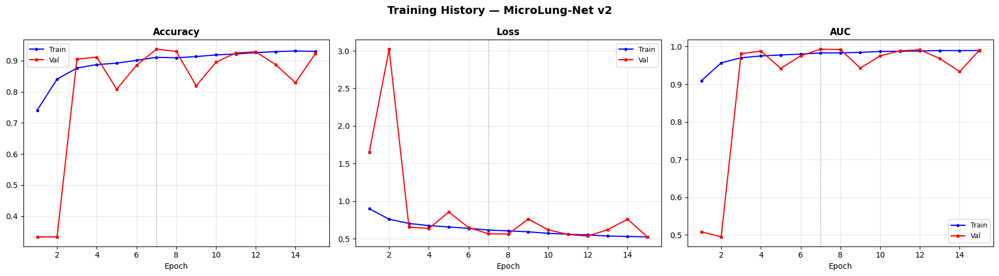

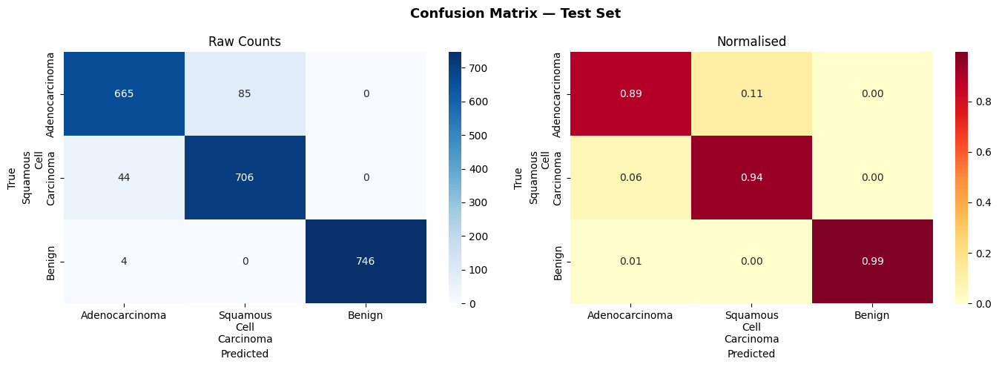

✅ Section 6 complete


In [10]:
# Training curves
hist       = history.history
epochs_ran = range(1, len(hist['loss']) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Training History — MicroLung-Net v2', fontsize=14, fontweight='bold')

for ax, (t_key, v_key, title) in zip(axes, [
    ('accuracy', 'val_accuracy', 'Accuracy'),
    ('loss',     'val_loss',     'Loss'),
    ('auc',      'val_auc',      'AUC'),
]):
    ax.plot(epochs_ran, hist[t_key], 'b-o', ms=3, lw=1.5, label='Train')
    ax.plot(epochs_ran, hist[v_key], 'r-s', ms=3, lw=1.5, label='Val')
    ax.axvline(best_ep+1, color='gray', lw=1, ls=':')
    ax.set_title(title, fontweight='bold'); ax.set_xlabel('Epoch')
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/training_history.png', dpi=150, bbox_inches='tight')
plt.show()

# Confusion matrices
cm_arr  = confusion_matrix(y_true, y_pred)
cm_norm = cm_arr.astype('float') / cm_arr.sum(axis=1, keepdims=True)
labels_cm = [c.replace('_','\n').title() for c in CLASS_NAMES]

fig2, axes2 = plt.subplots(1, 2, figsize=(14, 5))
fig2.suptitle('Confusion Matrix — Test Set', fontsize=13, fontweight='bold')
sns.heatmap(cm_arr,  annot=True, fmt='d',   cmap='Blues',  xticklabels=labels_cm, yticklabels=labels_cm, ax=axes2[0])
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='YlOrRd', xticklabels=labels_cm, yticklabels=labels_cm, ax=axes2[1])
for ax2, t in zip(axes2, ['Raw Counts','Normalised']):
    ax2.set_title(t); ax2.set_ylabel('True'); ax2.set_xlabel('Predicted')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Section 6 complete")

✅ Grad-CAM helpers defined


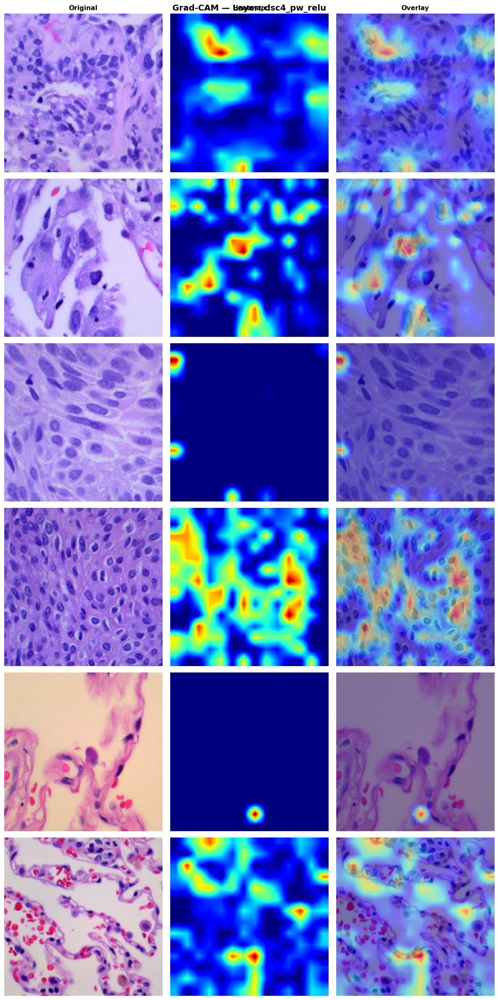

✅ Section 7 complete


In [11]:
def load_image_np(path):
    """Load one image as (H,W,3) float32 in [0,1]."""
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    return (tf.cast(img, tf.float32) / 255.0).numpy()


def get_gradcam(model, img_array, last_conv_name, pred_index=None):
    """img_array: (1,H,W,3). Returns heatmap (h,w) in [0,1] and pred class."""
    grad_model = Model(
        inputs  = model.inputs,
        outputs = [model.get_layer(last_conv_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_array, training=False)
        if pred_index is None:
            pred_index = int(tf.argmax(preds[0]))
        score = preds[:, pred_index]

    grads   = tape.gradient(score, conv_out)               # (1,h,w,c)
    weights = tf.reduce_mean(grads, axis=(0,1,2))          # (c,)
    heatmap = conv_out[0] @ weights[..., tf.newaxis]       # (h,w,1)
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), pred_index


def make_overlay(img_np, heatmap, alpha=0.45):
    """Returns (H,W,3) uint8 overlay."""
    hm_up    = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))
    hm_color = mpl_cm.jet(hm_up)[:,:,:3]
    img_u8   = (img_np   * 255).astype(np.uint8)
    hm_u8    = (hm_color * 255).astype(np.uint8)
    return cv2.addWeighted(img_u8, 1-alpha, hm_u8, alpha, 0)


print("✅ Grad-CAM helpers defined")

# Plot 2 samples per class
N_GCAM = 2
fig, axes = plt.subplots(NUM_CLASSES * N_GCAM, 3, figsize=(12, 4*NUM_CLASSES*N_GCAM))
fig.suptitle(f'Grad-CAM — Layer: {LAST_CONV}', fontsize=14, fontweight='bold')

for ci, ct in enumerate(['Original', 'Heatmap', 'Overlay']):
    axes[0][ci].set_title(ct, fontsize=11, fontweight='bold')

row = 0
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    sample_idxs = np.where(y_test == cls_idx)[0][:N_GCAM]
    for sidx in sample_idxs:
        img_np    = load_image_np(X_test[sidx])
        img_batch = np.expand_dims(img_np, 0).astype(np.float32)
        probs     = model.predict(img_batch, verbose=0)[0]
        heatmap, pred_cls = get_gradcam(model, img_batch, LAST_CONV)
        hm_up     = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))
        overlay   = make_overlay(img_np, heatmap)

        ax_r = axes[row]
        ax_r[0].imshow(img_np)
        ax_r[0].set_ylabel(f"True:\n{cls_name.split('_')[0].title()}", fontsize=8)
        ax_r[0].axis('off')
        ax_r[1].imshow(hm_up, cmap='jet')
        ax_r[1].axis('off')
        correct = '✅' if pred_cls == cls_idx else '❌'
        ax_r[2].imshow(overlay)
        ax_r[2].set_xlabel(
            f"{correct} {CLASS_NAMES[pred_cls].split('_')[0].title()} ({probs[pred_cls]:.2f})",
            fontsize=8
        )
        ax_r[2].axis('off')
        row += 1

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/gradcam_visualization.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Section 7 complete")

Running confidence drop test ...
  adenocarcinoma                      mean_drop=0.0566 ±0.0995
  squamous_cell_carcinoma             mean_drop=0.4355 ±0.1551
  benign                              mean_drop=0.0653 ±0.0563

  Overall mean drop : 0.1858
  ✅ Discriminative regions confirmed.


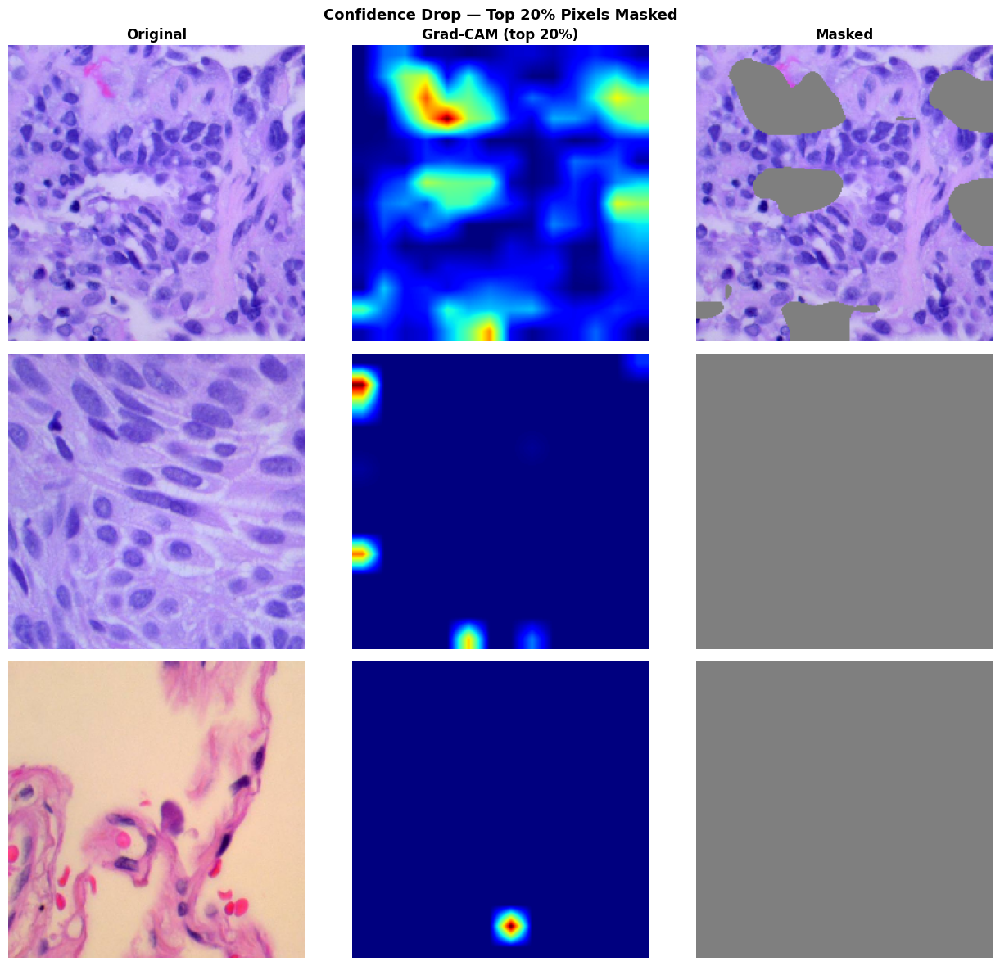

✅ Section 8 complete


In [12]:
def confidence_drop_test(model, img_path, top_pct=0.20):
    img_np    = load_image_np(img_path)
    img_batch = np.expand_dims(img_np, 0).astype(np.float32)

    probs_orig = model.predict(img_batch, verbose=0)[0]
    pred_idx   = int(np.argmax(probs_orig))
    orig_conf  = float(probs_orig[pred_idx])

    heatmap, _ = get_gradcam(model, img_batch, LAST_CONV, pred_index=pred_idx)
    hm_full    = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))

    threshold  = np.percentile(hm_full, (1 - top_pct) * 100)
    mask_bool  = hm_full >= threshold
    masked_img = img_np.copy()
    masked_img[mask_bool] = 0.5

    probs_masked = model.predict(
        np.expand_dims(masked_img, 0).astype(np.float32), verbose=0
    )[0]
    masked_conf = float(probs_masked[pred_idx])

    return {
        'orig_conf': orig_conf, 'masked_conf': masked_conf,
        'drop': orig_conf - masked_conf, 'pred_idx': pred_idx,
        'img_np': img_np, 'masked_img': masked_img, 'hm_full': hm_full
    }


# Run on 6 samples per class
all_drops    = []
cdt_results  = {}

print("Running confidence drop test ...")
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    idxs = np.where(y_test == cls_idx)[0][:6]
    records = [confidence_drop_test(model, X_test[i]) for i in idxs]
    cdt_results[cls_name] = records
    drops = [r['drop'] for r in records]
    all_drops.extend(drops)
    print(f"  {cls_name:<35} mean_drop={np.mean(drops):.4f} ±{np.std(drops):.4f}")

overall_drop = float(np.mean(all_drops))
print(f"\n  Overall mean drop : {overall_drop:.4f}")
print(f"  {'✅ Discriminative regions confirmed.' if overall_drop > 0.05 else '⚠️ Low drop.'}")

# Visualise one demo per class
fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(13, 4*NUM_CLASSES))
fig.suptitle('Confidence Drop — Top 20% Pixels Masked', fontsize=13, fontweight='bold')
for ci, ct in enumerate(['Original','Grad-CAM (top 20%)','Masked']):
    axes[0][ci].set_title(ct, fontweight='bold')

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    r = cdt_results[cls_name][0]
    axes[cls_idx][0].imshow(r['img_np'])
    axes[cls_idx][0].set_ylabel(cls_name.replace('_','\n').title(), fontsize=8); axes[cls_idx][0].axis('off')
    axes[cls_idx][1].imshow(r['hm_full'], cmap='jet'); axes[cls_idx][1].axis('off')
    axes[cls_idx][2].imshow(r['masked_img'])
    axes[cls_idx][2].set_xlabel(
        f"orig={r['orig_conf']:.3f}  masked={r['masked_conf']:.3f}  Δ={r['drop']:.3f}",
        fontsize=8
    )
    axes[cls_idx][2].axis('off')

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/confidence_drop_demo.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Section 8 complete")

Loading 300 images for robustness test ...
Loaded. Shape: (300, 224, 224, 3)

══════════════════════════════════════════════════════════════════════
 ROBUSTNESS RESULTS
══════════════════════════════════════════════════════════════════════
  Perturbation                         Acc     ΔAcc      F1      ΔF1
----------------------------------------------------------------------
  Clean Baseline                    0.9467       —   0.9467       —
  Gaussian Noise (σ=0.06)           0.7400  +0.2067  0.7357  +0.2110
  Gaussian Blur  (σ=2px)            0.9167  +0.0300  0.9168  +0.0299
  Brightness +35%                   0.7900  +0.1567  0.7983  +0.1484
══════════════════════════════════════════════════════════════════════


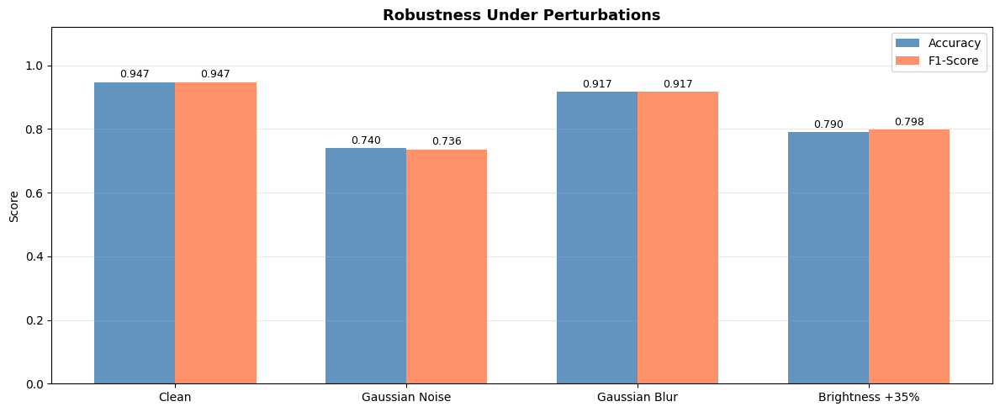

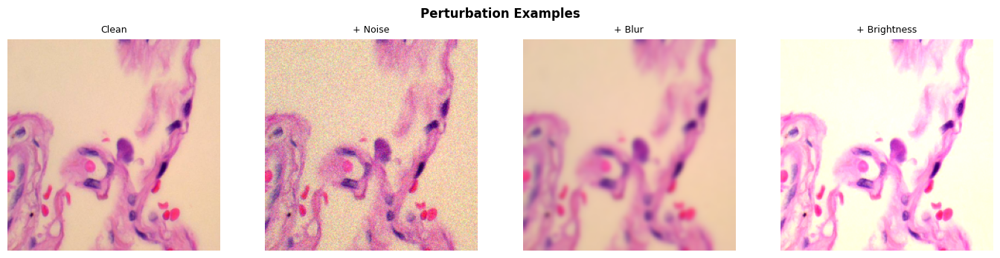

✅ Section 9 complete


In [13]:
N_ROB      = min(300, len(X_test))
rob_paths  = X_test[:N_ROB]
rob_labels = y_test[:N_ROB]

print(f"Loading {N_ROB} images for robustness test ...")
clean_imgs = np.stack([load_image_np(p) for p in rob_paths]).astype(np.float32)
print(f"Loaded. Shape: {clean_imgs.shape}")


def predict_acc_f1(imgs):
    preds = []
    for i in range(0, len(imgs), BATCH_SIZE):
        p = model.predict(imgs[i:i+BATCH_SIZE], verbose=0)
        preds.extend(np.argmax(p, axis=1))
    preds = np.array(preds)
    return (
        float(np.mean(preds == rob_labels)),
        float(f1_score(rob_labels, preds, average='weighted', zero_division=0))
    )


def add_noise(imgs, sigma=0.06):
    return np.clip(imgs + np.random.normal(0, sigma, imgs.shape).astype(np.float32), 0, 1)

def add_blur(imgs, sigma=2):
    ksize = int(6*sigma+1)|1
    return np.stack([
        cv2.GaussianBlur((img*255).astype(np.uint8),(ksize,ksize),sigma).astype(np.float32)/255
        for img in imgs
    ])

def add_brightness(imgs, factor=1.35):
    return np.clip(imgs * factor, 0, 1)


base_acc, base_f1 = predict_acc_f1(clean_imgs)

perturbations = [
    ('Gaussian Noise (σ=0.06)', add_noise(clean_imgs)),
    ('Gaussian Blur  (σ=2px)',  add_blur(clean_imgs)),
    ('Brightness +35%',         add_brightness(clean_imgs)),
]

rob_rows = []
print("\n" + "═"*70)
print(" ROBUSTNESS RESULTS")
print("═"*70)
print(f"  {'Perturbation':<32}  {'Acc':>6}  {'ΔAcc':>7}  {'F1':>6}  {'ΔF1':>7}")
print("-"*70)
print(f"  {'Clean Baseline':<32}  {base_acc:.4f}       —   {base_f1:.4f}       —")

for name, pert_imgs in perturbations:
    acc_p, f1_p = predict_acc_f1(pert_imgs)
    d_acc, d_f1 = base_acc - acc_p, base_f1 - f1_p
    rob_rows.append((name, acc_p, d_acc, f1_p, d_f1))
    print(f"  {name:<32}  {acc_p:.4f}  {d_acc:+.4f}  {f1_p:.4f}  {d_f1:+.4f}")
print("═"*70)

# Bar chart
r_labels = ['Clean'] + [r[0].split('(')[0].strip() for r in rob_rows]
r_accs   = [base_acc] + [r[1] for r in rob_rows]
r_f1s    = [base_f1]  + [r[3] for r in rob_rows]
x_r = np.arange(len(r_labels)); w = 0.35

fig, ax = plt.subplots(figsize=(12, 5))
b1 = ax.bar(x_r-w/2, r_accs, w, label='Accuracy', color='steelblue', alpha=0.85)
b2 = ax.bar(x_r+w/2, r_f1s,  w, label='F1-Score',  color='coral',    alpha=0.85)
ax.set_xticks(x_r); ax.set_xticklabels(r_labels, fontsize=10)
ax.set_title('Robustness Under Perturbations', fontweight='bold', fontsize=13)
ax.set_ylim(0, 1.12); ax.set_ylabel('Score'); ax.legend(); ax.grid(axis='y', alpha=0.3)
for b in list(b1)+list(b2):
    ax.annotate(f'{b.get_height():.3f}',
                xy=(b.get_x()+b.get_width()/2, b.get_height()),
                xytext=(0,4), textcoords='offset points', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/robustness_results.png', dpi=150, bbox_inches='tight')
plt.show()

# Sample perturbation grid
demo = clean_imgs[0]
demos = [('Clean',demo),('+ Noise',add_noise(demo[None])[0]),
         ('+ Blur',add_blur(demo[None])[0]),('+ Brightness',add_brightness(demo[None])[0])]
fig2, axes2 = plt.subplots(1, 4, figsize=(14, 3.5))
fig2.suptitle('Perturbation Examples', fontweight='bold')
for ax2,(t,img_d) in zip(axes2,demos):
    ax2.imshow(img_d); ax2.set_title(t, fontsize=9); ax2.axis('off')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/perturbation_examples.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Section 9 complete")


════════════════════════════════════════════════════════════
  ⚡ EFFICIENCY REPORT
════════════════════════════════════════════════════════════
  Parameters  :      731,843   ✅ (< 1M)
  Model size  :      8.517 MB   ✅ (< 10 MB)
  Infer mean  :      31.33 ms   ✅ (< 100 ms)
  Infer p95   :      36.88 ms
════════════════════════════════════════════════════════════


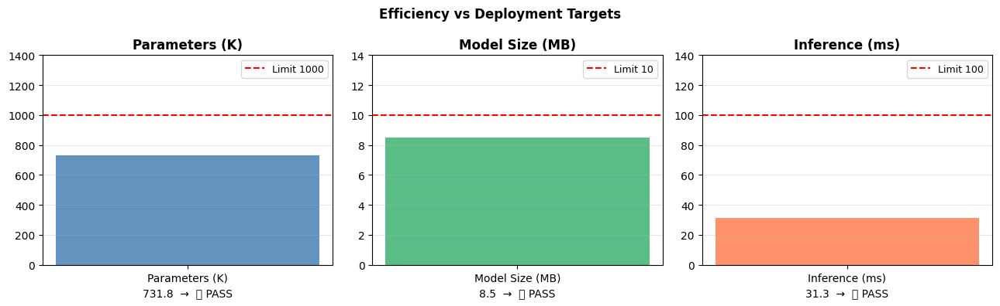

✅ Section 10 complete


In [14]:
# Parameters
total_params = model.count_params()

# Model size on disk
save_path = f'{OUT_DIR}/microlungnet_final.keras'
model.save(save_path)
model_size_mb = os.path.getsize(save_path) / (1024**2)

# CPU inference time (200 timed runs after 20 warm-up)
dummy = np.random.rand(1, IMG_SIZE, IMG_SIZE, 3).astype(np.float32)
with tf.device('/CPU:0'):
    for _ in range(20):
        _ = model(dummy, training=False)
    times = []
    for _ in range(200):
        t0 = time.perf_counter()
        _ = model(dummy, training=False)
        times.append((time.perf_counter()-t0)*1000)

mean_ms = float(np.mean(times))
p95_ms  = float(np.percentile(times, 95))

print("\n" + "═"*60)
print("  ⚡ EFFICIENCY REPORT")
print("═"*60)
print(f"  Parameters  : {total_params:>12,}   {'✅' if total_params<1_000_000 else '❌'} (< 1M)")
print(f"  Model size  : {model_size_mb:>10.3f} MB   {'✅' if model_size_mb<10 else '❌'} (< 10 MB)")
print(f"  Infer mean  : {mean_ms:>10.2f} ms   {'✅' if mean_ms<100 else '❌'} (< 100 ms)")
print(f"  Infer p95   : {p95_ms:>10.2f} ms")
print("═"*60)

# Bar chart vs limits
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
fig.suptitle('Efficiency vs Deployment Targets', fontweight='bold')
for ax, (label, val, lim, col) in zip(axes, [
    ('Parameters (K)', total_params/1000, 1000, 'steelblue'),
    ('Model Size (MB)', model_size_mb,    10,   'mediumseagreen'),
    ('Inference (ms)',  mean_ms,          100,  'coral'),
]):
    ax.bar([label], [val], color=col, alpha=0.85, width=0.5)
    ax.axhline(lim, color='red', ls='--', lw=1.5, label=f'Limit {lim}')
    ax.set_title(label, fontweight='bold')
    ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)
    ax.set_xlabel(f'{val:.1f}  →  {"✅ PASS" if val<lim else "❌ FAIL"}', fontsize=10)
    ax.set_ylim(0, lim*1.4)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/efficiency_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Section 10 complete")

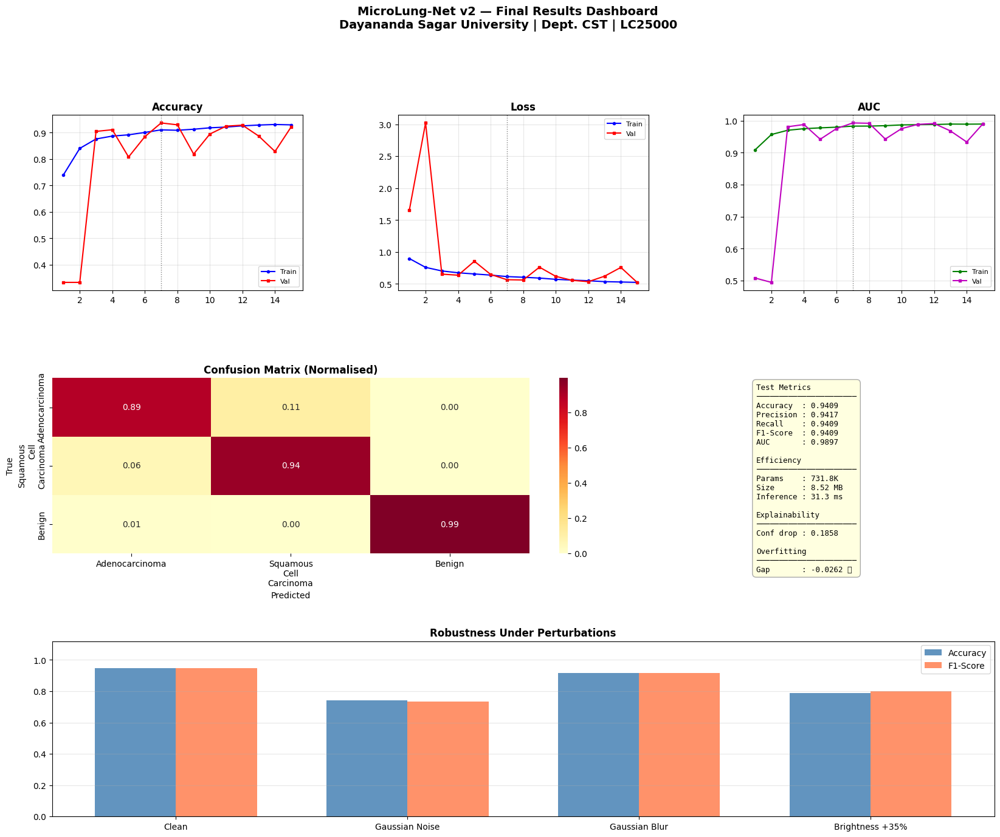


██████████████████████████████████████████████████████████████
  MICROLUNGNET v2 — ALL SECTIONS COMPLETE
██████████████████████████████████████████████████████████████
  Accuracy   : 94.09%  ✅ ≥85%
  F1-Score   : 0.9409
  AUC        : 0.9897
  Parameters : 731,843  ✅
  Model size : 8.52 MB  ✅
  Inference  : 31.3 ms  ✅
  Train gap  : -0.0262  ✅

📁 Saved outputs:
   __notebook__.ipynb                               (14539.5 KB)
   augmented_samples.png                            (2873.4 KB)
   best_model.keras                                 (8721.6 KB)
   class_distribution.png                           (32.1 KB)
   confidence_drop_demo.png                         (1380.4 KB)
   confusion_matrix.png                             (83.0 KB)
   efficiency_metrics.png                           (55.7 KB)
   final_dashboard.png                              (251.5 KB)
   gradcam_visualization.png                        (5351.4 KB)
   microlungnet_final.keras                         (8721.6 KB)
 

In [15]:
fig = plt.figure(figsize=(20, 15))
fig.suptitle(
    'MicroLung-Net v2 — Final Results Dashboard\n'
    'Dayananda Sagar University | Dept. CST | LC25000',
    fontsize=14, fontweight='bold', y=1.00
)
gs = fig.add_gridspec(3, 3, hspace=0.50, wspace=0.38)

# Accuracy
ax1 = fig.add_subplot(gs[0,0])
ax1.plot(epochs_ran, hist['accuracy'],     'b-o', ms=3, lw=1.5, label='Train')
ax1.plot(epochs_ran, hist['val_accuracy'], 'r-s', ms=3, lw=1.5, label='Val')
ax1.axvline(best_ep+1, color='gray', lw=1, ls=':')
ax1.set_title('Accuracy', fontweight='bold'); ax1.legend(fontsize=8); ax1.grid(alpha=0.3)

# Loss
ax2 = fig.add_subplot(gs[0,1])
ax2.plot(epochs_ran, hist['loss'],     'b-o', ms=3, lw=1.5, label='Train')
ax2.plot(epochs_ran, hist['val_loss'], 'r-s', ms=3, lw=1.5, label='Val')
ax2.axvline(best_ep+1, color='gray', lw=1, ls=':')
ax2.set_title('Loss', fontweight='bold'); ax2.legend(fontsize=8); ax2.grid(alpha=0.3)

# AUC
ax3 = fig.add_subplot(gs[0,2])
ax3.plot(epochs_ran, hist.get('auc',[0]*len(epochs_ran)),     'g-o', ms=3, lw=1.5, label='Train')
ax3.plot(epochs_ran, hist.get('val_auc',[0]*len(epochs_ran)), 'm-s', ms=3, lw=1.5, label='Val')
ax3.axvline(best_ep+1, color='gray', lw=1, ls=':')
ax3.set_title('AUC', fontweight='bold'); ax3.legend(fontsize=8); ax3.grid(alpha=0.3)

# Normalised confusion matrix
ax4 = fig.add_subplot(gs[1,:2])
labels_cm = [c.replace('_','\n').title() for c in CLASS_NAMES]
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='YlOrRd',
            xticklabels=labels_cm, yticklabels=labels_cm, ax=ax4)
ax4.set_title('Confusion Matrix (Normalised)', fontweight='bold')
ax4.set_ylabel('True'); ax4.set_xlabel('Predicted')

# Metrics text box
ax5 = fig.add_subplot(gs[1,2])
ax5.axis('off')
summary = (
    f"Test Metrics\n{'─'*22}\n"
    f"Accuracy  : {acc:.4f}\n"
    f"Precision : {prec:.4f}\n"
    f"Recall    : {rec:.4f}\n"
    f"F1-Score  : {f1:.4f}\n"
    f"AUC       : {auc:.4f}\n\n"
    f"Efficiency\n{'─'*22}\n"
    f"Params    : {total_params/1e3:.1f}K\n"
    f"Size      : {model_size_mb:.2f} MB\n"
    f"Inference : {mean_ms:.1f} ms\n\n"
    f"Explainability\n{'─'*22}\n"
    f"Conf drop : {overall_drop:.4f}\n\n"
    f"Overfitting\n{'─'*22}\n"
    f"Gap       : {gap:+.4f} {'✅' if gap<0.08 else '⚠️'}"
)
ax5.text(0.05, 0.97, summary, transform=ax5.transAxes,
         fontsize=9, va='top', fontfamily='monospace',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='lightyellow', edgecolor='#aaa'))

# Robustness bar chart
ax6 = fig.add_subplot(gs[2,:])
r_labels = ['Clean'] + [r[0].split('(')[0].strip() for r in rob_rows]
r_accs   = [base_acc] + [r[1] for r in rob_rows]
r_f1s    = [base_f1]  + [r[3] for r in rob_rows]
x_r = np.arange(len(r_labels)); w_r = 0.35
ax6.bar(x_r-w_r/2, r_accs, w_r, label='Accuracy', color='steelblue', alpha=0.85)
ax6.bar(x_r+w_r/2, r_f1s,  w_r, label='F1-Score',  color='coral',    alpha=0.85)
ax6.set_xticks(x_r); ax6.set_xticklabels(r_labels, fontsize=10)
ax6.set_title('Robustness Under Perturbations', fontweight='bold')
ax6.set_ylim(0, 1.12); ax6.legend(); ax6.grid(axis='y', alpha=0.3)

plt.savefig(f'{OUT_DIR}/final_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

# Final summary
print("\n" + "█"*62)
print("  MICROLUNGNET v2 — ALL SECTIONS COMPLETE")
print("█"*62)
print(f"  Accuracy   : {acc*100:.2f}%  {'✅ ≥85%' if acc>=0.85 else '📈 below target'}")
print(f"  F1-Score   : {f1:.4f}")
print(f"  AUC        : {auc:.4f}")
print(f"  Parameters : {total_params:,}  {'✅' if total_params<1_000_000 else '❌'}")
print(f"  Model size : {model_size_mb:.2f} MB  {'✅' if model_size_mb<10 else '❌'}")
print(f"  Inference  : {mean_ms:.1f} ms  {'✅' if mean_ms<100 else '❌'}")
print(f"  Train gap  : {gap:+.4f}  {'✅' if gap<0.08 else '⚠️'}")
print("\n📁 Saved outputs:")
for f_name in sorted(os.listdir(OUT_DIR)):
    fp = os.path.join(OUT_DIR, f_name)
    if os.path.isfile(fp):
        print(f"   {f_name:<48} ({os.path.getsize(fp)/1024:.1f} KB)")
print("█"*62)

In [16]:
model.save('/kaggle/working/microlungnet_final.keras')